# 04 - Comparaison des optimiseurs

On entraîne **le même MLP** (2 × 64, ReLU) avec les optimiseurs vus en cours :

| Optimiseur | Idée |
|---|---|
| **SGD** | $w \leftarrow w - \eta \, \nabla L$ |
| **SGD + momentum** | ajoute une « inertie » : la mise à jour précédente est réutilisée |
| **AdaGrad** | learning rate adapté à chaque poids selon la somme des gradients au carré (ralentit avec le temps) |
| **RMSprop** | AdaGrad avec un facteur d'oubli $\rho$ sur l'accumulation |
| **Adam** | momentum + learning rate adaptatif ($\beta_1 = 0.9$, $\beta_2 = 0.999$) |
| **Adamax** | variante d'Adam basée sur la norme infinie |

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from velo_utils import load_splits, plot_history, PALETTE

keras.utils.set_random_seed(42)  # reproductibilité
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


In [2]:
X_train, X_test, y_train, y_test = load_splits()
Xtr, Xte = X_train.to_numpy(), X_test.to_numpy()
ytr, yte = y_train.to_numpy(), y_test.to_numpy()
n_features = Xtr.shape[1]
print("train :", Xtr.shape, "| test :", Xte.shape)

train : (585, 33) | test : (146, 33)


In [3]:
def make_model(hidden=(64, 64), optimizer=None, X=None):
    """MLP : Normalization -> couches cachées ReLU -> 1 sortie linéaire."""
    X = Xtr if X is None else X
    norm = layers.Normalization()
    norm.adapt(X)
    model = keras.Sequential([keras.Input(shape=(X.shape[1],)), norm])
    for units in hidden:
        model.add(layers.Dense(units, activation="relu"))
    model.add(layers.Dense(1))
    model.compile(optimizer=optimizer or keras.optimizers.Adam(learning_rate=1e-3), loss="mae")
    return model

## 1. Même architecture, optimiseurs différents

In [4]:
optimizers = {
    "SGD": lambda: keras.optimizers.SGD(learning_rate=0.01),
    "SGD + momentum": lambda: keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "AdaGrad": lambda: keras.optimizers.Adagrad(learning_rate=0.01),
    "RMSprop": lambda: keras.optimizers.RMSprop(learning_rate=0.001, rho=0.9),
    "Adam": lambda: keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999),
    "Adamax": lambda: keras.optimizers.Adamax(learning_rate=0.002),
}

histories, rows = {}, []
for name, make_opt in optimizers.items():
    keras.utils.set_random_seed(42)  # mêmes poids initiaux pour tous
    model = make_model(optimizer=make_opt())
    start = time.time()
    histories[name] = model.fit(Xtr, ytr, epochs=100, batch_size=32, validation_split=0.2, verbose=0)
    val = histories[name].history["val_loss"]
    rows.append({
        "optimiseur": name,
        "temps (s)": round(time.time() - start, 1),
        "meilleure MAE val": round(min(val), 3),
        "époque du min": int(np.argmin(val)) + 1,
        "MAE test": round(model.evaluate(Xte, yte, verbose=0), 3),
    })

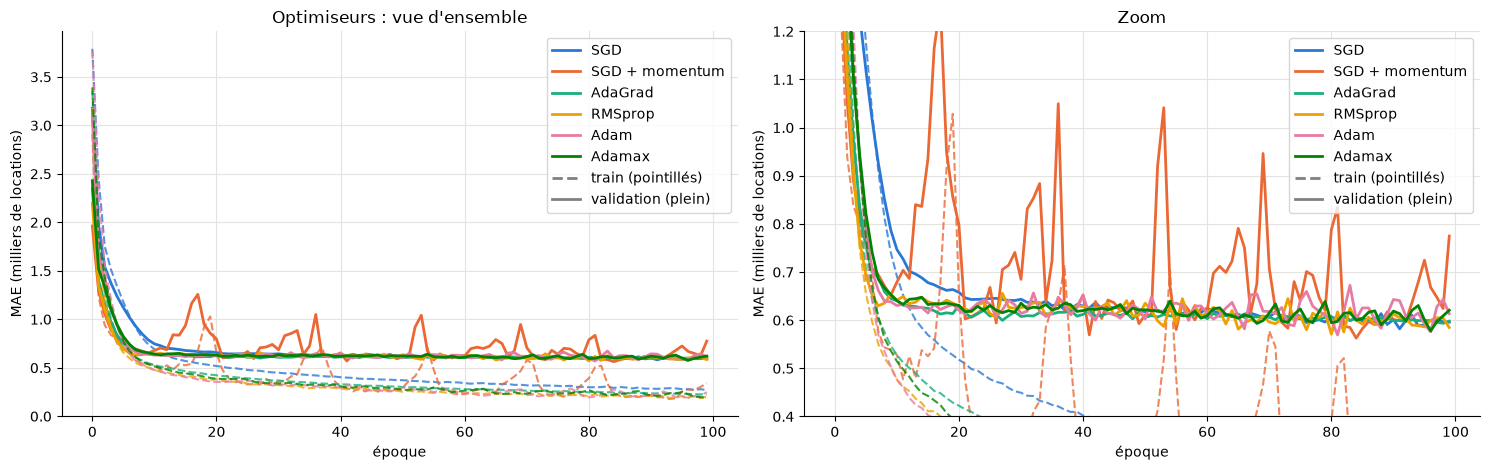

,temps (s),meilleure MAE val,époque du min,MAE test
optimiseur,,,,
Adamax,13.2,0.578,97,0.563
RMSprop,17.6,0.571,81,0.574
Adam,16.6,0.569,82,0.579
AdaGrad,18.2,0.594,99,0.586
SGD,15.1,0.581,97,0.617
SGD + momentum,13.1,0.563,85,0.804


In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8))
plot_history(histories, title="Optimiseurs : vue d'ensemble", ax=ax1)
plot_history(histories, title="Zoom", ylim=(0.4, 1.2), ax=ax2)
plt.tight_layout()
plt.show()

pd.DataFrame(rows).set_index("optimiseur").sort_values("MAE test")

Comparez la **meilleure MAE de validation** et la **MAE de test** (calculée avec les poids de la *dernière* époque) :
un optimiseur dont la courbe oscille peut avoir atteint un bon minimum puis en être ressorti.
C'est souvent le cas de SGD + momentum avec ce learning rate : l'inertie amplifie les pas.

## 2. Influence du learning rate (Adam)

Le learning rate reste l'hyperparamètre le plus important :
trop petit, l'apprentissage est lent ; trop grand, il devient instable.

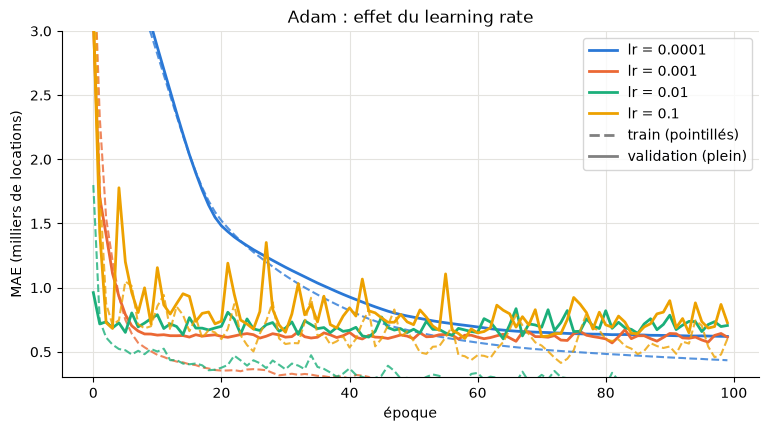

,MAE test
learning rate,
0.0001,0.639
0.0010,0.579
0.0100,0.586
0.1000,0.670


In [6]:
lr_histories, rows = {}, []
for lr in [1e-4, 1e-3, 1e-2, 1e-1]:
    keras.utils.set_random_seed(42)
    model = make_model(optimizer=keras.optimizers.Adam(learning_rate=lr))
    lr_histories[f"lr = {lr:g}"] = model.fit(Xtr, ytr, epochs=100, validation_split=0.2, verbose=0)
    rows.append({"learning rate": lr, "MAE test": round(model.evaluate(Xte, yte, verbose=0), 3)})

plot_history(lr_histories, title="Adam : effet du learning rate", ylim=(0.3, 3)); plt.show()
pd.DataFrame(rows).set_index("learning rate")

## 3. Réduire le learning rate en cours d'entraînement

Le callback `ReduceLROnPlateau` divise le learning rate quand la perte de validation stagne :
on démarre vite, puis on affine.

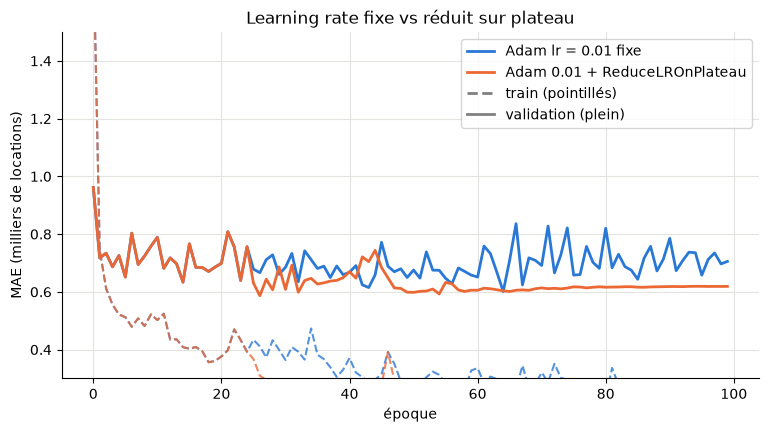

MAE test : 0.522


In [7]:
keras.utils.set_random_seed(42)
model = make_model(optimizer=keras.optimizers.Adam(learning_rate=1e-2))
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-5)
h_plateau = model.fit(Xtr, ytr, epochs=100, validation_split=0.2, callbacks=[reduce_lr], verbose=0)

plot_history({"Adam lr = 0.01 fixe": lr_histories["lr = 0.01"], "Adam 0.01 + ReduceLROnPlateau": h_plateau},
             title="Learning rate fixe vs réduit sur plateau", ylim=(0.3, 1.5))
plt.show()
print("MAE test :", round(model.evaluate(Xte, yte, verbose=0), 3))

## À vous de jouer

- Faites varier `momentum` (0.5, 0.9, 0.99) pour SGD.
- Donnez à AdaGrad un learning rate plus grand (0.1) : rattrape-t-il les autres ?
- Changez `beta_1` / `beta_2` d'Adam et observez l'effet sur la stabilité des courbes.
- Relancez avec une autre graine (`keras.utils.set_random_seed`) : le classement des optimiseurs est-il stable ?